In [1]:
import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python 경로:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Python: 3.8.8 (default, Apr 13 2021, 19:58:26) 
[GCC 7.3.0]
Python 경로: /home/junea/anaconda3/bin/python
PyTorch: 2.4.1+cu121
CUDA: True


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 이미지 데이터를 Tensor로 변환
transform = transforms.ToTensor()

# 학습 데이터셋
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# 테스트 데이터셋
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("학습 데이터:", len(train_dataset))
print("테스트 데이터:", len(test_dataset))

학습 데이터: 60000
테스트 데이터: 10000


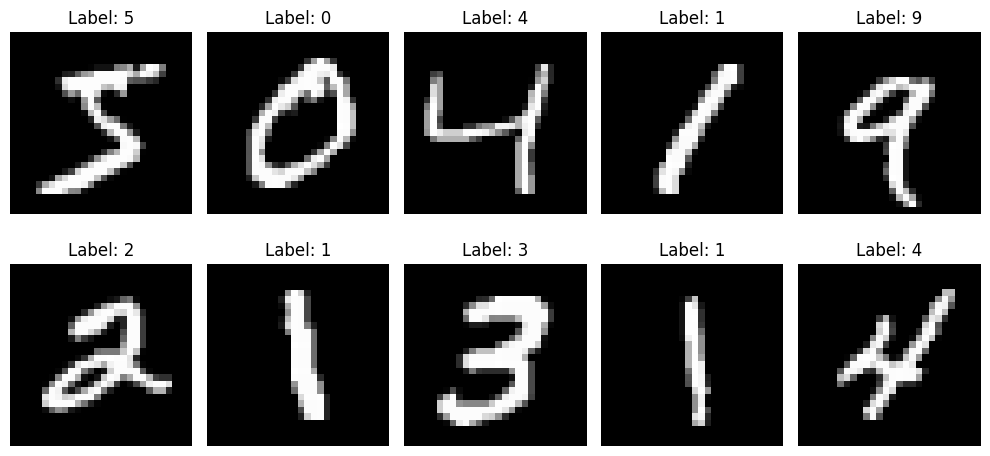

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# 하나의 배치 확인
images, labels = next(iter(train_loader))

print("이미지 Tensor:", images.shape)
print("정답 Tensor:", labels.shape)

이미지 Tensor: torch.Size([64, 1, 28, 28])
정답 Tensor: torch.Size([64])


In [5]:

import torch
import torch.nn as nn

# CNN 모델 정의
class CNN(nn.Module):       # cnn 모델 정의
    def __init__(self):
        super().__init__()

        # 이미지 특징 추출
        self.conv = nn.Sequential(

            nn.ReLU(),

            # 1: 입력 이미지의 채널 수, 16: 출력 채널 수, kernel_size=3: 필터 크기, padding=1: 입력 이미지 주변에 1픽셀 패딩
            nn.Conv2d(1, 16, kernel_size=3, padding=1),      

            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),

            # Relu = 음수는 0으로, 양수는 그대로 출력하는 활성화 함수
            nn.ReLU(),
            
            nn.MaxPool2d(kernel_size=2)
        )

        # 숫자 분류
        self.fc = nn.Linear(32 * 7 * 7, 10)     # 특징 확보 후 10개의 숫자 분류

    def forward(self, x):                       # 흐름: 이미지 받음 -> 특징 추출 -> 펼치기 -> 분류 
        x = self.conv(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

# CPU 또는 GPU 선택
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 모델 생성
model = CNN().to(device)

print(model)
print("사용 장치:", device)


CNN(
  (conv): Sequential(
    (0): ReLU()
    (1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Linear(in_features=1568, out_features=10, bias=True)
)
사용 장치: cuda


In [6]:

# DataLoader에서 이미지 64장 가져오기
images, labels = next(iter(train_loader))

# 모델이 사용하는 장치로 이동
images = images.to(device)

# CNN 모델에 이미지 입력
with torch.no_grad():
    outputs = model(images)

print("입력 이미지 크기:", images.shape)
print("모델 출력 크기:", outputs.shape)
print("첫 번째 이미지의 예측 점수:", outputs[0])


입력 이미지 크기: torch.Size([64, 1, 28, 28])
모델 출력 크기: torch.Size([64, 10])
첫 번째 이미지의 예측 점수: tensor([ 0.0810,  0.0798,  0.2103, -0.0564, -0.1077, -0.2432, -0.0625,  0.0770,
         0.0237,  0.0472], device='cuda:0')


In [7]:

# 손실 함수
criterion = nn.CrossEntropyLoss()

# 최적화 알고리즘
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# 학습 횟수
epochs = 5

print("Loss Function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Epochs:", epochs)


Loss Function: CrossEntropyLoss()
Optimizer: Adam
Epochs: 5


In [8]:

# 학습 결과 저장
train_losses = []
train_accuracies = []

# 모델 학습
for epoch in range(epochs):

    model.train()  # 학습 모드

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # CPU 또는 GPU로 데이터 이동
        images = images.to(device)
        labels = labels.to(device)

        # 1. 이전 기울기 초기화
        optimizer.zero_grad()

        # 2. 순전파 (Forward)
        outputs = model(images)

        # 3. 손실 계산
        loss = criterion(outputs, labels)

        # 4. 역전파 (Backward)
        loss.backward()

        # 5. 가중치 업데이트
        optimizer.step()

        # Loss 누적
        running_loss += loss.item() * images.size(0)

        # 예측 결과 확인
        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Epoch별 평균 Loss와 정확도
    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


Epoch [1/5] Loss: 0.2355 Accuracy: 93.07%
Epoch [2/5] Loss: 0.0687 Accuracy: 97.89%
Epoch [3/5] Loss: 0.0508 Accuracy: 98.44%
Epoch [4/5] Loss: 0.0413 Accuracy: 98.69%
Epoch [5/5] Loss: 0.0336 Accuracy: 98.98%


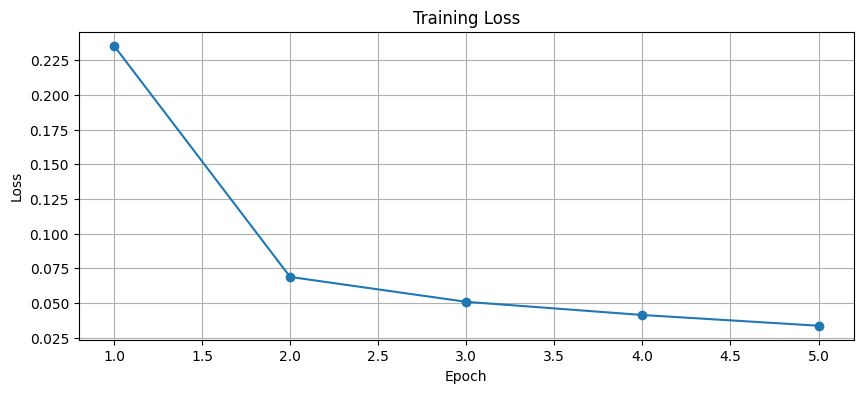

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


In [10]:

# 모델을 평가 모드로 변경
model.eval()

correct = 0
total = 0

# 기울기 계산 비활성화
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 모델 예측
        outputs = model(images)

        # 가장 높은 점수를 가진 숫자 선택
        predicted = outputs.argmax(dim=1)

        # 전체 데이터 수
        total += labels.size(0)

        # 정답 개수
        correct += (predicted == labels).sum().item()

# 정확도 계산
accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")


Test Accuracy: 98.88%


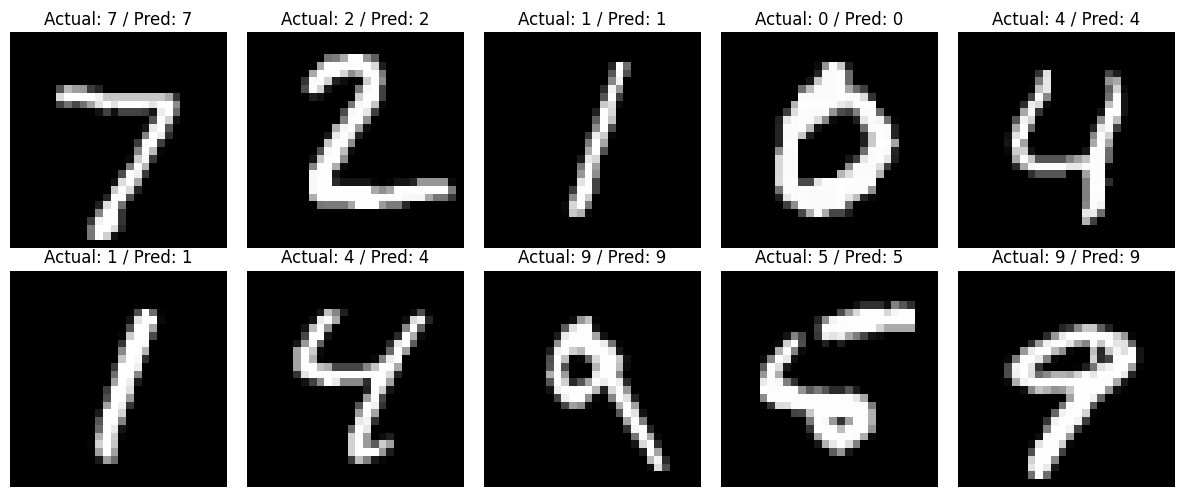

In [11]:

import matplotlib.pyplot as plt

# 테스트 데이터에서 한 배치 가져오기
images, labels = next(iter(test_loader))

# 모델 예측
model.eval()

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

# 이미지 10개 시각화
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image = images[i].squeeze()

    ax.imshow(image, cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    ax.set_title(
        f"Actual: {actual} / Pred: {predicted}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:

import os

# 모델 저장 폴더 생성
os.makedirs("models", exist_ok=True)

# 학습된 가중치 저장
torch.save(
    model.state_dict(),
    "models/mnist_cnn.pth"
)

print("모델 저장 완료!")


모델 저장 완료!


In [13]:

# 새로운 CNN 객체 생성
loaded_model = CNN().to(device)

# 저장한 모델 가중치 불러오기
state_dict = torch.load(
    "models/mnist_cnn.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(state_dict)

# 평가 모드
loaded_model.eval()

print("모델 로드 완료!")


모델 로드 완료!


In [14]:

model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))

        # 숫자별 예측 확률
        probabilities = torch.softmax(outputs, dim=1)

        # 가장 높은 확률과 예측 숫자
        confidences, predictions = probabilities.max(dim=1)

        # 틀린 이미지 찾기
        wrong_mask = predictions.cpu() != labels

        wrong_images.extend(images[wrong_mask])
        wrong_labels.extend(labels[wrong_mask].tolist())
        wrong_predictions.extend(
            predictions.cpu()[wrong_mask].tolist()
        )
        wrong_confidences.extend(
            confidences.cpu()[wrong_mask].tolist()
        )

print("전체 테스트 이미지:", len(test_dataset))
print("틀린 이미지:", len(wrong_images))
print(
    "오류율:",
    f"{len(wrong_images) / len(test_dataset) * 100:.2f}%"
)


전체 테스트 이미지: 10000
틀린 이미지: 112
오류율: 1.12%


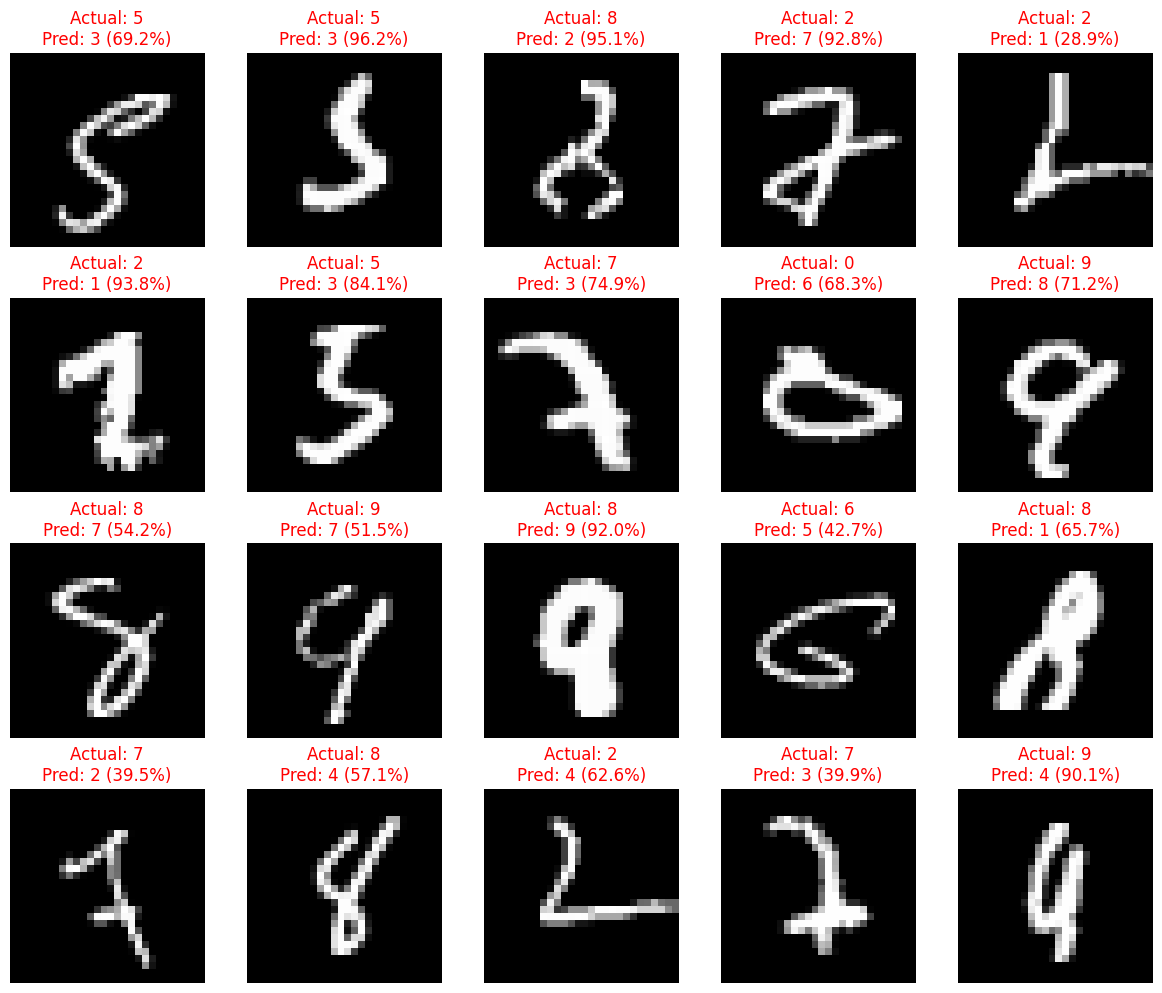

In [15]:

# 틀린 이미지 최대 20개 출력
n = min(20, len(wrong_images))

if n == 0:
    print("틀린 이미지가 없습니다.")
else:
    fig, axes = plt.subplots(4, 5, figsize=(12, 10))

    for i, ax in enumerate(axes.flat):
        if i < n:
            ax.imshow(
                wrong_images[i].squeeze(),
                cmap="gray"
            )

            actual = wrong_labels[i]
            predicted = wrong_predictions[i]
            confidence = wrong_confidences[i] * 100

            ax.set_title(
                f"Actual: {actual}\n"                           # actual: 실제 숫자
                f"Pred: {predicted} ({confidence:.1f}%)",       # predicted: 모델이 예측한 숫자, confidence: 예측 확률
                color="red"
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


숫자별 오분류 횟수
숫자 0: 8개
숫자 1: 0개
숫자 2: 15개
숫자 3: 5개
숫자 4: 3개
숫자 5: 21개
숫자 6: 14개
숫자 7: 11개
숫자 8: 15개
숫자 9: 20개


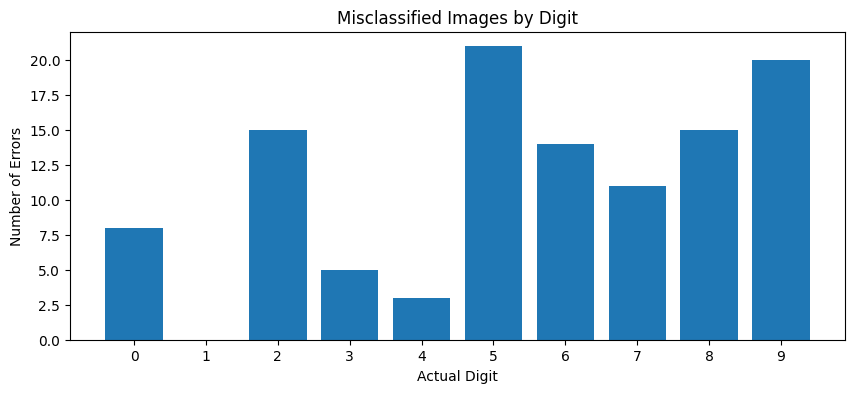

In [16]:

from collections import Counter

# 실제 정답 기준으로 오분류 횟수 계산
wrong_count = Counter(wrong_labels)

print("숫자별 오분류 횟수")

for digit in range(10):
    print(
        f"숫자 {digit}: "
        f"{wrong_count[digit]}개"
    )

# 그래프 출력
plt.figure(figsize=(10, 4))

plt.bar(
    range(10),
    [wrong_count[i] for i in range(10)]
)

plt.xlabel("Actual Digit")
plt.ylabel("Number of Errors")
plt.title("Misclassified Images by Digit")
plt.xticks(range(10))
plt.show()


/home/junea/.local/lib/python3.8/site-packages/sklearn/utils/multiclass.py:13: DeprecationWarning: Please use `spmatrix` from the `scipy.sparse` namespace, the `scipy.sparse.base` namespace is deprecated.
  from scipy.sparse.base import spmatrix


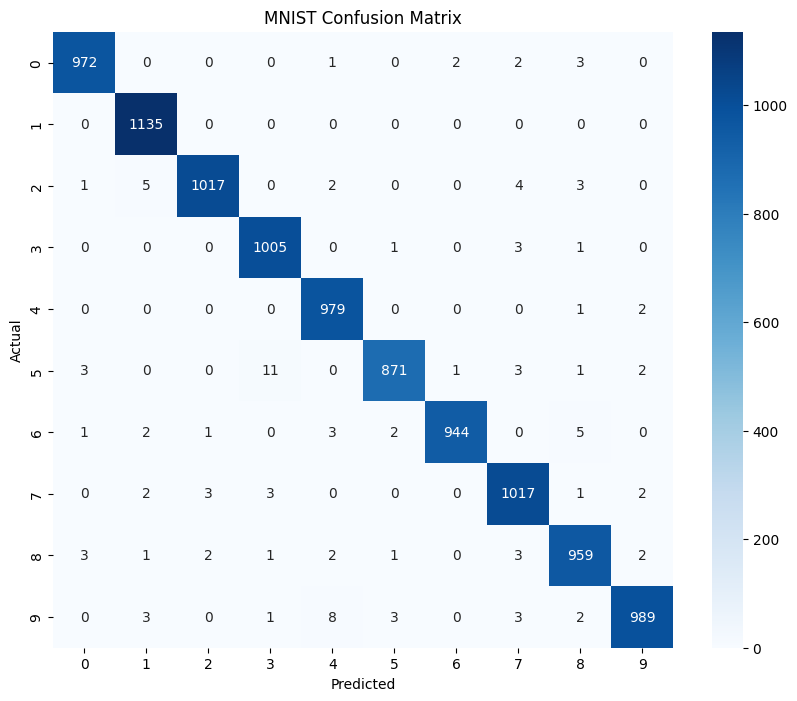

In [17]:

from sklearn.metrics import confusion_matrix
import seaborn as sns

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(
            predictions.cpu().tolist()
        )

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MNIST Confusion Matrix")
plt.show()


In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 전체 정확도
accuracy = accuracy_score(all_labels, all_predictions)

# 정밀도
precision = precision_score(
    all_labels, all_predictions,
    average="macro"
)

# 재현율
recall = recall_score(
    all_labels, all_predictions,
    average="macro"
)

# F1-score
f1 = f1_score(
    all_labels, all_predictions,
    average="macro"
)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

print("\n숫자별 평가 결과")
print(classification_report(
    all_labels,
    all_predictions
))


Accuracy : 98.88%
Precision: 98.89%
Recall   : 98.85%
F1-score : 98.87%

숫자별 평가 결과
             precision    recall  f1-score   support

          0       0.99      0.99      0.99       980
          1       0.99      1.00      0.99      1135
          2       0.99      0.99      0.99      1032
          3       0.98      1.00      0.99      1010
          4       0.98      1.00      0.99       982
          5       0.99      0.98      0.98       892
          6       1.00      0.99      0.99       958
          7       0.98      0.99      0.99      1028
          8       0.98      0.98      0.98       974
          9       0.99      0.98      0.99      1009

avg / total       0.99      0.99      0.99     10000




## 1. MNIST 성능 평가에 사용하는 5가지 지표

| 평가지표 | 의미 | 확인 목적 |
|---|---|---|
| **Accuracy** | 전체 숫자 중 정답을 맞힌 비율 | 모델의 전체 분류 성능 |
| **Precision** | 특정 숫자라고 예측한 것 중 실제로 맞힌 비율 | 잘못된 숫자 예측 분석 |
| **Recall** | 실제 특정 숫자 중 올바르게 찾아낸 비율 | 숫자별 인식 누락 분석 |
| **F1-score** | Precision과 Recall의 조화평균 | 숫자별 분류 성능 종합 |
| **Confusion Matrix** | 실제 숫자와 예측 숫자의 관계 | 어떤 숫자끼리 혼동하는지 분석 |

---

## 2. 연구 목적에 따른 핵심 평가지표

| 연구 목적 | 핵심 평가지표 |
|---|---|
| MNIST 기본 숫자 분류 | Accuracy, Macro F1 |
| 숫자별 오분류 분석 | Precision, Recall, Confusion Matrix |
| 예측 신뢰도 분석 | ECE, NLL |
| 노이즈에 대한 강건성 분석 | 노이즈 강도별 Accuracy, Macro F1 |
| Denoising 이미지 복원 | PSNR, SSIM, MSE |
| Jetson 추론 성능 | Latency, FPS, 메모리, 전력 소비 |


In [19]:

def add_noise(images, noise_level=0.3):             # 노이즈를 추가하는 함수 정의, images: 이미지 Tensor, noise_level: 노이즈 강도
    noise = torch.randn_like(images) * noise_level  # 원본 이미지와 크기가 같은 Tensor를 만들고, 각 위치에 정규분포를 따르는 무작위 숫자 생성
    noisy_images = images + noise                   # 원본 이미지의 각 픽셀 값에 노이즈를 더함

    return torch.clamp(noisy_images, 0.0, 1.0)      # 픽셀 값이 0.0~1.0 범위를 벗어나지 않도록 제한


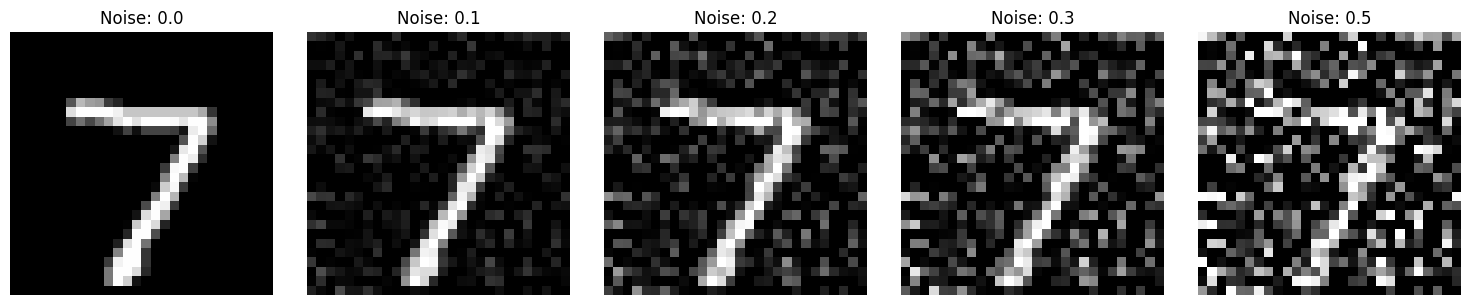

In [20]:

# 원본 이미지 가져오기
image, label = test_dataset[0]

# 노이즈 강도 변경
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.5]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

# 같은 노이즈 패턴을 강도별로 비교
torch.manual_seed(42)
base_noise = torch.randn_like(image)

for i, level in enumerate(noise_levels):
    noisy_image = torch.clamp(
        image + base_noise * level, 0.0, 1.0
    )

    axes[i].imshow(
        noisy_image.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"Noise: {level}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [21]:

from sklearn.metrics import accuracy_score, f1_score

# 실험할 노이즈 강도
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.5]

# 실험 결과 저장
results = []

# 모델 평가 모드
model.eval()

for level in noise_levels:
    all_true = []
    all_pred = []

    # 재현 가능한 실험을 위한 난수 고정
    torch.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:

            # 이미지에 Gaussian Noise 추가
            noisy_images = add_noise(images, level)

            # 이미지 데이터를 CPU 또는 GPU로 이동
            noisy_images = noisy_images.to(device)

            # CNN 모델 예측
            outputs = model(noisy_images)

            # 가장 높은 점수의 숫자 선택
            predictions = outputs.argmax(dim=1)

            # 실제 정답 및 예측 결과 저장
            all_true.extend(labels.tolist())
            all_pred.extend(
                predictions.cpu().tolist()
            )

    # 성능 지표 계산
    accuracy = accuracy_score(all_true, all_pred)
    f1 = f1_score(
        all_true, all_pred, average="macro"
    )

    # 결과 저장
    results.append({
        "noise": level,
        "accuracy": accuracy,
        "f1": f1
    })

    print(
        f"Noise: {level:.1f} | "
        f"Accuracy: {accuracy * 100:.2f}% | "
        f"F1-score: {f1 * 100:.2f}%"
    )


Noise: 0.0 | Accuracy: 98.88% | F1-score: 98.87%
Noise: 0.1 | Accuracy: 98.68% | F1-score: 98.67%
Noise: 0.2 | Accuracy: 98.13% | F1-score: 98.11%
Noise: 0.3 | Accuracy: 95.00% | F1-score: 94.98%
Noise: 0.5 | Accuracy: 58.01% | F1-score: 58.00%


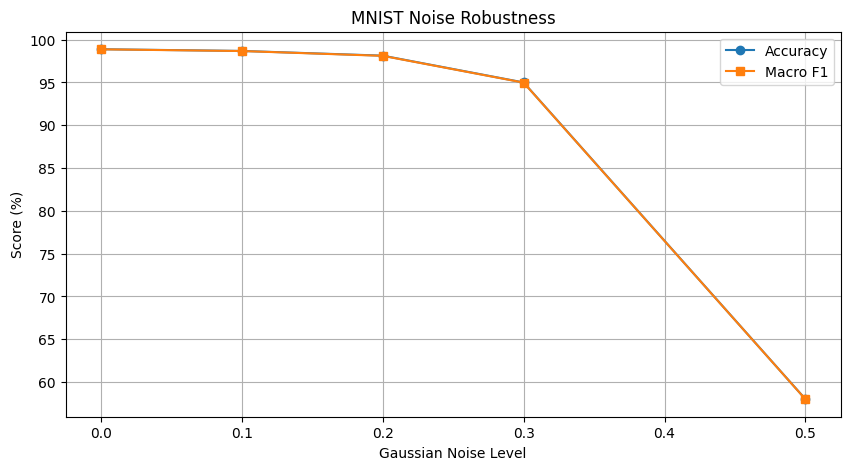

In [22]:

# 결과 데이터 분리
levels = [r["noise"] for r in results]
accuracies = [r["accuracy"] * 100 for r in results]
f1_scores = [r["f1"] * 100 for r in results]

# 그래프 출력
plt.figure(figsize=(10, 5))

plt.plot(
    levels,
    accuracies,
    marker="o",
    label="Accuracy"
)

plt.plot(
    levels,
    f1_scores,
    marker="s",
    label="Macro F1"
)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Score (%)")
plt.title("MNIST Noise Robustness")

plt.legend()
plt.grid(True)
plt.show()
